In [1]:
import os
from pathlib import Path

import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine

# Find the project root (works whether the notebook runs from analysis/ or the root)
PROJECT_ROOT = Path.cwd() if (Path.cwd() / ".env").exists() else Path.cwd().parent
load_dotenv(PROJECT_ROOT / ".env")

engine = create_engine(
    f"postgresql+psycopg2://{os.environ['POSTGRES_USER']}:{os.environ['POSTGRES_PASSWORD']}"
    f"@localhost:5433/{os.environ['POSTGRES_DB']}"
)


def q(sql):
    """Run a SQL query against the warehouse and return the result as a table."""
    return pd.read_sql(sql, engine)

## 1. What share of delivered orders arrive late?

In [2]:
q("""
SELECT
    COUNT(*)                              AS delivered_orders,
    ROUND(100.0 * AVG(is_late::int), 1)   AS pct_late
FROM analytics.fct_order_delivery
""")

,delivered_orders,pct_late
0,96470,6.8


**Finding:** Of 96,470 delivered orders, 6.8% (about 6,500) arrived after the
estimated delivery date, so roughly 93% were on time. On its own this number
doesn't tell us whether performance is good or bad — it needs context: a target,
a trend over time, and how severe and how widespread the delays are. The next
questions provide that context.

## 2. How did the late-delivery rate change month by month?

,purchase_month,orders,pct_late
0,2016-10-01,265,0.8
1,2017-01-01,750,2.9
2,2017-02-01,1653,3.0
3,2017-03-01,2546,4.6
4,2017-04-01,2303,6.6
5,2017-05-01,3545,3.0
6,2017-06-01,3135,3.0
7,2017-07-01,3872,2.8
8,2017-08-01,4193,2.9
9,2017-09-01,4150,4.4


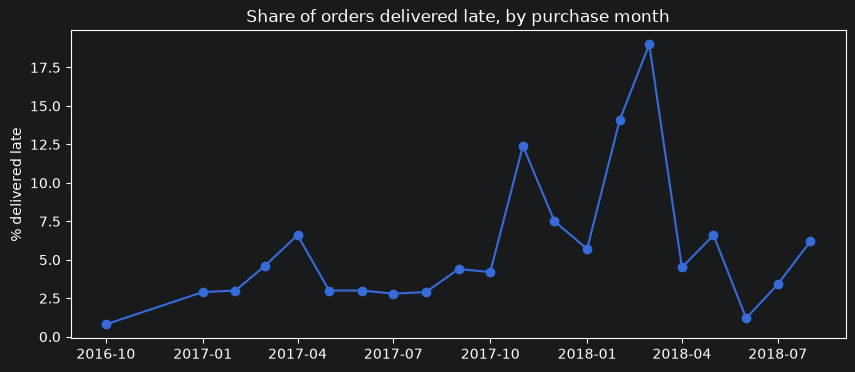

In [3]:
monthly = q("""
SELECT
    purchase_month,
    COUNT(*)                              AS orders,
    ROUND(100.0 * AVG(is_late::int), 1)   AS pct_late
FROM analytics.fct_order_delivery
GROUP BY purchase_month
HAVING COUNT(*) >= 100
ORDER BY purchase_month
""")

ax = monthly.plot(x="purchase_month", y="pct_late", marker="o", legend=False, figsize=(10, 4))
ax.set_title("Share of orders delivered late, by purchase month")
ax.set_ylabel("% delivered late")
ax.set_xlabel("")

(PROJECT_ROOT / "docs").mkdir(exist_ok=True)
ax.figure.savefig(PROJECT_ROOT / "docs" / "monthly_late_rate.png", dpi=150, bbox_inches="tight")

monthly

**Finding:** In most months, 3–5% of orders were delivered late. Three months
stand out: November 2017 (12.4%), February 2018 (14.1%) and March 2018 (19.0%).

The November spike coincides with a jump in order volume (~4,500 in October
to ~7,300), consistent with a Black Friday capacity crunch. February–March 2018
is different: volume stayed flat at around 7,000 orders per month, the same as
January (5.7% late). And from April 2018 onwards the late rate fell back to
normal levels even though volume remained above 6,000 orders a month.

So order volume alone does not explain the 2018 spike. The next question is
what changed in those two months — which part of the delivery chain caused it.

## 3. Were late deliveries caused by sellers or by carriers?

,purchase_month,seller_late,carrier_late,unknown
0,2016-10-01,2,0,0
1,2017-01-01,6,16,0
2,2017-02-01,29,20,0
3,2017-03-01,29,87,0
4,2017-04-01,46,105,0
5,2017-05-01,32,74,0
6,2017-06-01,35,60,0
7,2017-07-01,21,87,0
8,2017-08-01,35,87,0
9,2017-09-01,45,136,1


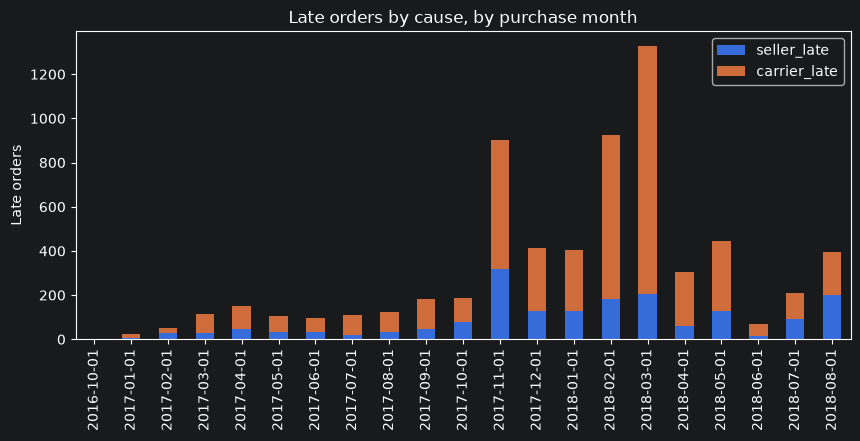

In [4]:
causes = q("""
SELECT
    purchase_month,
    COUNT(*) FILTER (WHERE delay_cause = 'seller')   AS seller_late,
    COUNT(*) FILTER (WHERE delay_cause = 'carrier')  AS carrier_late,
    COUNT(*) FILTER (WHERE delay_cause = 'unknown')  AS unknown
FROM analytics.fct_order_delivery
GROUP BY purchase_month
HAVING COUNT(*) >= 100
ORDER BY purchase_month
""")

ax = causes.plot(x="purchase_month", y=["seller_late", "carrier_late"],
                 kind="bar", stacked=True, figsize=(10, 4))
ax.set_title("Late orders by cause, by purchase month")
ax.set_ylabel("Late orders")
ax.set_xlabel("")
ax.figure.savefig(PROJECT_ROOT / "docs" / "late_orders_by_cause.png", dpi=150, bbox_inches="tight")

causes

In [5]:
rates = q("""
SELECT
    purchase_month,
    COUNT(*)                                                            AS orders,
    ROUND(100.0 * AVG((delay_cause = 'seller')::int), 1)                AS seller_late_pct,
    ROUND(100.0 * AVG((delay_cause = 'carrier')::int), 1)               AS carrier_late_pct
FROM analytics.fct_order_delivery
WHERE purchase_month BETWEEN '2017-10-01' AND '2018-05-01'
GROUP BY purchase_month
ORDER BY purchase_month
""")
rates

,purchase_month,orders,seller_late_pct,carrier_late_pct
0,2017-10-01,4478,1.8,2.4
1,2017-11-01,7288,4.4,8.0
2,2017-12-01,5513,2.3,5.2
3,2018-01-01,7069,1.8,3.9
4,2018-02-01,6555,2.8,11.3
5,2018-03-01,7003,2.9,16.0
6,2018-04-01,6798,0.9,3.6
7,2018-05-01,6749,1.9,4.7


**Finding:** Looking at counts alone is misleading, because months with more
orders naturally have more late orders. Comparing late *rates* gives a clearer
picture — and shows the two spikes were different kinds of problem:

- **November 2017 (whole-chain capacity problem):** order volume jumped 63%
  versus October, and both seller-caused (1.8% → 4.4%) and carrier-caused
  (2.4% → 8.0%) late rates rose sharply.
- **February–March 2018 (transport problem):** volume was flat, seller-caused
  lateness rose only slightly (1.8% → 2.9%), but carrier-caused lateness
  quadrupled (3.9% → 16.0%). Carrier rates rose about 11 times more than
  seller rates.
- **August 2018:** seller delays matched carrier delays in count for the first
  time — a new pattern worth monitoring.

**Next steps:** identify sellers who are repeatedly late; break carrier delays
down by region; investigate what happened in the carrier network in early 2018.
The dataset does not name the carrier, so carrier-level analysis would require
data from the logistics partner.

## 4. Where were carrier delays worst?

,customer_state,jan_orders,jan_carrier_late_pct,febmar_orders,febmar_carrier_late_pct
0,SP,2975,1.8,5603,6.5
1,RJ,850,10.2,1743,29.4
2,MG,846,1.5,1646,11.2
3,RS,367,6.5,770,13.9
4,PR,371,0.8,704,9.1
5,SC,311,8.0,501,17.2
6,BA,228,4.4,443,22.8
7,DF,135,0.7,317,10.4
8,GO,144,3.5,287,16.4
9,ES,145,6.2,282,23.0


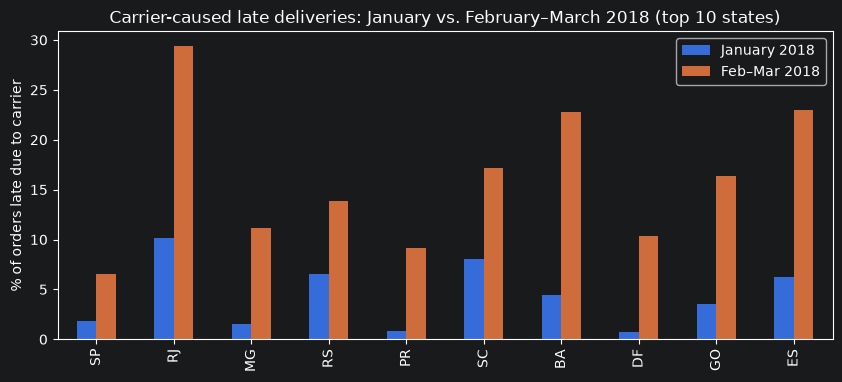

In [6]:
states = q("""
SELECT
    customer_state,
    COUNT(*) FILTER (WHERE purchase_month = '2018-01-01')                     AS jan_orders,
    ROUND(100.0 * COUNT(*) FILTER (WHERE purchase_month = '2018-01-01' AND delay_cause = 'carrier')
        / NULLIF(COUNT(*) FILTER (WHERE purchase_month = '2018-01-01'), 0), 1)  AS jan_carrier_late_pct,
    COUNT(*) FILTER (WHERE purchase_month IN ('2018-02-01', '2018-03-01'))    AS febmar_orders,
    ROUND(100.0 * COUNT(*) FILTER (WHERE purchase_month IN ('2018-02-01', '2018-03-01') AND delay_cause = 'carrier')
        / NULLIF(COUNT(*) FILTER (WHERE purchase_month IN ('2018-02-01', '2018-03-01')), 0), 1) AS febmar_carrier_late_pct
FROM analytics.fct_order_delivery
GROUP BY customer_state
ORDER BY febmar_orders DESC
LIMIT 10
""")

ax = states.plot(x="customer_state", y=["jan_carrier_late_pct", "febmar_carrier_late_pct"],
                 kind="bar", figsize=(10, 4))
ax.set_title("Carrier-caused late deliveries: January vs. February–March 2018 (top 10 states)")
ax.set_ylabel("% of orders late due to carrier")
ax.set_xlabel("")
ax.legend(["January 2018", "Feb–Mar 2018"])
ax.figure.savefig(PROJECT_ROOT / "docs" / "carrier_late_by_state.png", dpi=150, bbox_inches="tight")

states

In [7]:
from scipy.stats import spearmanr

states["increase_pts"] = states["febmar_carrier_late_pct"] - states["jan_carrier_late_pct"]

rho, p_value = spearmanr(states["jan_carrier_late_pct"], states["increase_pts"])
print(f"Spearman correlation between January rate and Feb–Mar increase: {rho:.2f} (p = {p_value:.2f})")

states[["customer_state", "jan_carrier_late_pct", "febmar_carrier_late_pct", "increase_pts"]]

Spearman correlation between January rate and Feb–Mar increase: 0.31 (p = 0.38)


,customer_state,jan_carrier_late_pct,febmar_carrier_late_pct,increase_pts
0,SP,1.8,6.5,4.7
1,RJ,10.2,29.4,19.2
2,MG,1.5,11.2,9.7
3,RS,6.5,13.9,7.4
4,PR,0.8,9.1,8.3
5,SC,8.0,17.2,9.2
6,BA,4.4,22.8,18.4
7,DF,0.7,10.4,9.7
8,GO,3.5,16.4,12.9
9,ES,6.2,23.0,16.8


**Finding:** The February–March 2018 carrier spike hit **every one of the top 10
states** — no region escaped, which points to a network-wide transport problem
rather than a local one.

- **Rio de Janeiro (RJ) has a structural problem on top of the spike:** 10.2%
  carrier-late even in a normal month (January), rising to 29.4% in Feb–Mar —
  almost 1 in 3 orders. As the second-largest market, this matters.
- **São Paulo (SP) performs best** despite the highest volume (1.8% → 6.5%),
  plausibly because most sellers are based there and delivery distances are short.
- **Some states were hit hard from a low base:** Bahia (BA) rose from 4.4% to
  22.8% (+18 points); Paraná (PR) and Distrito Federal (DF) rose roughly 11–15×,
  though only +8 to +10 points in absolute terms.
- **Did already-weak states suffer more?** A Spearman rank correlation between
  January rates and the Feb–Mar increase was weak and not significant
  (ρ = 0.31, p = 0.38, n = 10). The spike hit states broadly regardless of
  their normal performance.

**Recommendation:** treat RJ as a separate, structural issue (route, carrier or
estimate review), distinct from the temporary network-wide disruption.